## 03 . Coherence change detection and validation with USGS rupture mapping

**Step 3 of 4:** ASF search & download → SNAP coherence processing → **Python scene differencing** → statistical validation

### Method

Interferometric coherence (0–1) measures how similar the radar echo from each pixel is between two acquisitions. Stable ground stays coherent over 12 days. Surface rupture, fissuring, and strong shaking rearrange the scatterers and interupts coherence.

Following *Fielding et al. (2005)*, who used this approach to map the 2003 Bam, Iran rupture, we compare two coherence maps:

$$\Delta\gamma = \gamma_{\text{pre}} - \gamma_{\text{co}}$$

* $\gamma_{\text{pre}}$: coherence of a pair *before* the earthquakes, the "normal" background decorrelation
* $\gamma_{\text{co}}$: coherence of a pair *containing* the earthquakes

Subtracting should remove decorrelation that is present from sources of noise. What remains, **Δγ > 0**, is change caused by the event. we then check where that change falls relative to the field-verified rupture map from the USGS.

### Inputs
* Two terrain-corrected coherence GeoTIFFs exported from SNAP
* The AOI polygon
* USGS rupture traces: Ponti et al. (2020), doi:[10.5066/P9BZ5IJ9](https://doi.org/10.5066/P9BZ5IJ9)

In [2]:
# may not need to run this - I was having environment issues with GDAL
import os, sys
from pathlib import Path

if os.name == "nt":
    env = Path(sys.prefix)
    os.environ["PATH"] = str(env / "Library" / "bin") + os.pathsep + os.environ["PATH"]
    os.environ.setdefault("GDAL_DATA", str(env / "Library" / "share" / "gdal"))
    os.environ.setdefault("PROJ_DATA", str(env / "Library" / "share" / "proj"))
    os.environ.setdefault("PROJ_LIB",  str(env / "Library" / "share" / "proj"))

In [9]:
import os, sys
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from rasterio.warp import reproject, Resampling

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "src"))
import ccd_utils as ccd

## 1. Setting Repository Paths

In [4]:
DATA = REPO / "data"
PRE_COH = DATA / "processed" / "PreEventCoherence.tif"
CO_COH  = DATA / "processed" / "PostEventCoherence.tif"     
AOI_PATH = DATA / "aoi" / "AOI_Ridgecrest_CA.kml"
RUPTURE_PATH = DATA / "usgs" / "USGS_rupturetrace_v4.kml"                  # file from the USGS data release
rupture = gpd.read_file(RUPTURE_PATH)
OPTICAL = DATA / "aoi" / "Sentinel2_L2A_True_color20290718.tiff"

PRE_LABEL = "Pre-event coherence (10 June - 22 June 2019)"
CO_LABEL  = "Co-event coherence (04 July -16 July 2019)"

COH_BAND = None        # None = auto-detect the 'coh' band; set an int if your GeoTIFF needs it
CRS = ccd.DEFAULT_CRS  # UTM 11N, so distances are in metres
RESOLUTION = 10        # m, matches SNAP Terrain-Correction pixel spacing

OUT_DIR = DATA / "processed"
FIG_DIR = REPO / "figures"
FIG_DIR.mkdir(exist_ok=True)

## 2. Put both coherence maps on one grid

Images are resampled to a common 10 m UTM grid covering the AOI, with pixels outside the AOI masked. The UTM projection enables distance measurements during the validation step.

In [5]:
aoi = ccd.load_aoi(AOI_PATH)
transform, shape, crs = ccd.common_grid(aoi, crs=CRS, resolution=RESOLUTION)

coh_pre = ccd.mask_outside(ccd.to_grid(PRE_COH, transform, shape, crs, band=COH_BAND), aoi, transform, crs)
coh_co  = ccd.mask_outside(ccd.to_grid(CO_COH,  transform, shape, crs, band=COH_BAND), aoi, transform, crs)

# Plot extent in km (UTM) for every map below
extent_km = np.array([transform.c, transform.c + shape[1] * transform.a,
                      transform.f + shape[0] * transform.e, transform.f]) / 1000

print(f"Grid: {shape[1]} x {shape[0]} px at {RESOLUTION} m, {crs}")
for name, a in [("pre", coh_pre), ("co", coh_co)]:
    print(f"{name:>3}: mean coherence {np.nanmean(a):.2f}, valid {np.isfinite(a).mean():.0%}")

Grid: 4552 x 5574 px at 10 m, EPSG:32611
pre: mean coherence 0.69, valid 82%
 co: mean coherence 0.70, valid 82%


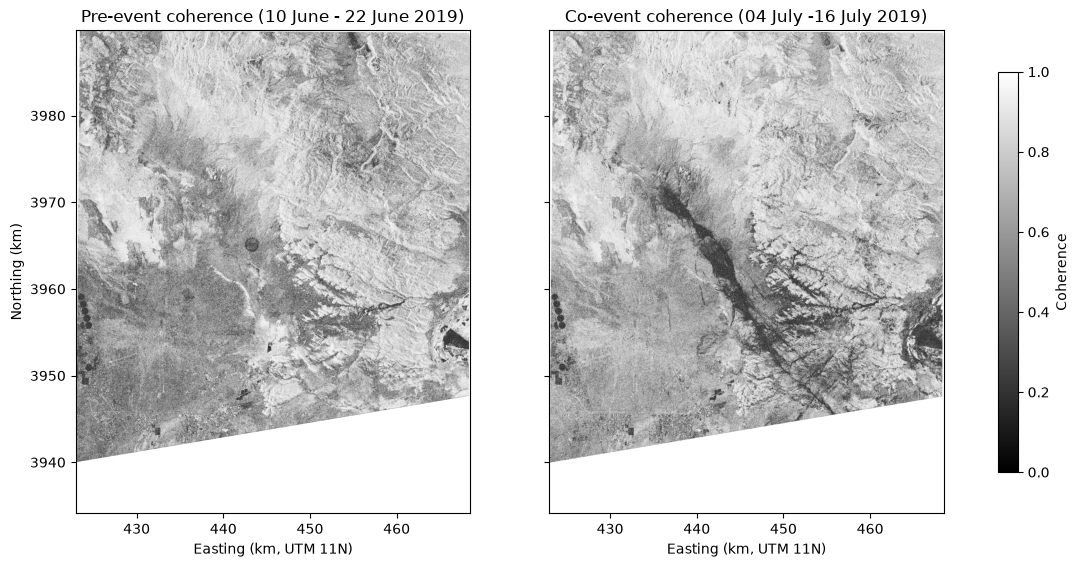

In [6]:
# Ploting pre and Co images for visulisation
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), sharex=True, sharey=True)
for ax, arr, title in zip(axes, [coh_pre, coh_co], [PRE_LABEL, CO_LABEL]):
    im = ax.imshow(arr, cmap="gray", vmin=0, vmax=1, extent=extent_km)
    ax.set_title(title)
    ax.set_xlabel("Easting (km, UTM 11N)")
axes[0].set_ylabel("Northing (km)")
fig.colorbar(im, ax=axes, shrink=0.8, label="Coherence")
plt.show()

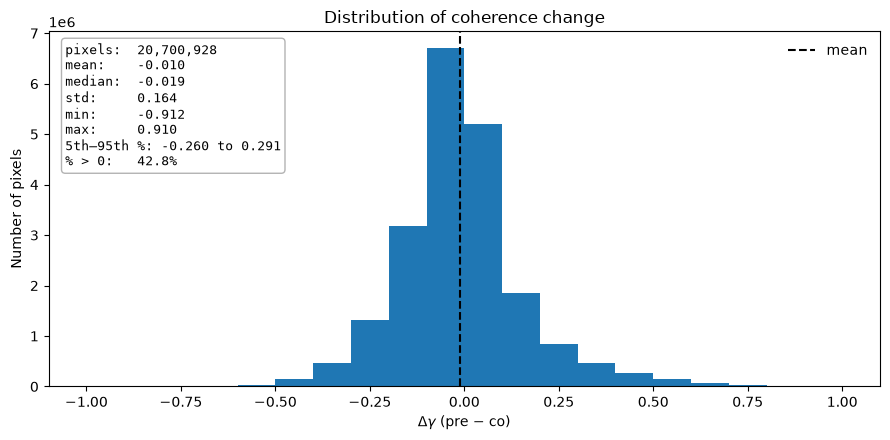

In [7]:
diff = ccd.coherence_difference(coh_pre, coh_co)
vals = diff[np.isfinite(diff)]   # drop no-data pixels

mean, median, std = vals.mean(), np.median(vals), vals.std()
p5, p95 = np.percentile(vals, [5, 95])
stats_text = "\n".join([
    f"pixels:  {vals.size:,}",
    f"mean:    {mean:.3f}",
    f"median:  {median:.3f}",
    f"std:     {std:.3f}",
    f"min:     {vals.min():.3f}",
    f"max:     {vals.max():.3f}",
    f"5th–95th %: {p5:.3f} to {p95:.3f}",
    f"% > 0:   {100 * np.mean(vals > 0):.1f}%",
])

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(vals, bins=20, range=(-1, 1))
ax.axvline(mean, color="k", ls="--", label="mean")
ax.text(0.02, 0.97, stats_text, transform=ax.transAxes, va="top", ha="left",
        family="monospace", fontsize=9,
        bbox=dict(boxstyle="round", facecolor="white", edgecolor="0.7"))
ax.set_xlabel(r"$\Delta\gamma$ (pre − co)")
ax.set_ylabel("Number of pixels")
ax.set_title("Distribution of coherence change")
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
fig.savefig(FIG_DIR / "CoherenceDistribution.png", dpi=150)
plt.show()

## 3. Coherence difference
Now we will over lay the results to see how well the USGS "ground truth" data maps over our coherence subtraction map. We will also add a background optical.

* **Δγ = pre − co**, the direct difference used by Fielding et al. (2005)

#### Overlay results with USGS mapped rupture:

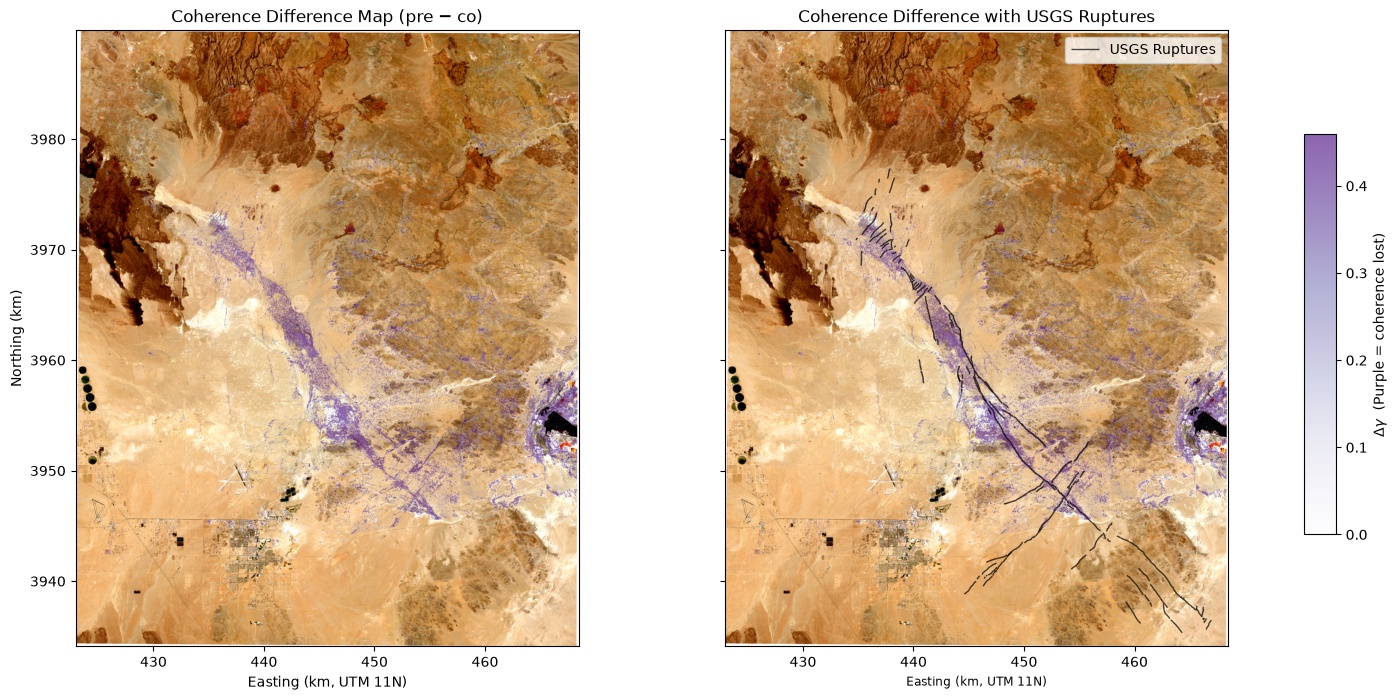

In [8]:
#diff = ccd.coherence_difference(coh_pre, coh_co)

# 1. Reproject the optical image onto the same 10 m UTM grid as diff
with rasterio.open(OPTICAL) as src:
    n_bands = min(src.count, 3)                      # RGB only (drops an alpha band if present)
    optical_img = np.full((n_bands, *shape), np.nan, dtype="float32")
    for b in range(n_bands):
        reproject(
            source=rasterio.band(src, b + 1),
            destination=optical_img[b],
            src_nodata=src.nodata,
            dst_transform=transform,
            dst_crs=crs,
            dst_nodata=np.nan,
            resampling=Resampling.bilinear,
        )
optical_img = np.moveaxis(optical_img, 0, -1)        # (rows, cols, bands)

# 2. Contrast stretch (2-98 %), no-data shown as white
valid = np.isfinite(optical_img) & (optical_img > 0)
p_low, p_high = np.percentile(optical_img[valid], (2, 98))
optical_img = np.clip((optical_img - p_low) / (p_high - p_low), 0, 1)
optical_img = np.nan_to_num(optical_img, nan=1.0)

# 3. Rupture traces in the same UTM CRS, scaled to km
rupture = gpd.read_file(RUPTURE_PATH).to_crs(crs)
rupture_km = rupture.copy()
rupture_km["geometry"] = rupture.geometry.scale(xfact=1e-3, yfact=1e-3, origin=(0, 0))

# 4. Two panels on the common grid (extent_km comes from section 2)
arr_plot = np.ma.masked_where(~(diff > 0.2), diff)
lim = np.nanpercentile(np.abs(diff), 98)

fig, axes = plt.subplots(1, 2, figsize=(16, 8), sharex=True, sharey=True)
for ax in axes:
    ax.imshow(optical_img, extent=extent_km, origin="upper")
    im = ax.imshow(arr_plot, cmap="Purples", vmin=0, vmax=lim,
                   extent=extent_km, alpha=0.6, origin="upper")

rupture_km.plot(ax=axes[1], color="black", linewidth=1, alpha=0.7, label="USGS Ruptures")

axes[0].set_title("Coherence Difference Map (pre − co)")
axes[1].set_title("Coherence Difference with USGS Ruptures")
axes[1].legend(loc="upper right")
for ax in axes:
    ax.set_xlim(extent_km[0], extent_km[1])
    ax.set_ylim(extent_km[2], extent_km[3])
    ax.set_aspect("equal")
    ax.set_xlabel("Easting (km, UTM 11N)")
axes[0].set_ylabel("Northing (km)")
axes[1].set_ylabel("")

# 5. Shared colorbar
cbar_ax = fig.add_axes([0.92, 0.25, 0.02, 0.5])
fig.colorbar(im, cax=cbar_ax, label=r"$\Delta\gamma$  (Purple = coherence lost)")
plt.subplots_adjust(wspace=0.1, right=0.9)
fig.savefig(FIG_DIR / "coherence_differencingMap_vs_usgs_rupture.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Findings and limitations

**Findings**

The masked coherence map highlights two areas of change between the observation periods. The first is a continuous northwest–southeast band running through the centre of the study area, corresponding to the main rupture. With the USGS rupture traces overlaid, the band closely follows the mapped rupture along most of its length. The uncovered section was not processed due to the edge of the SAR swath used in the analysis.

East of the rupture, a speckled zone of weaker coherence loss extends eastward, leading to a dense signal near the edge of the study area. Further investigation identifies this area as Searles Lake (https://en.wikipedia.org/wiki/Searles_Lake), which hosts mining operations by Searles Valley Minerals Inc. These activities explain the observed decorrelation in this area.

**Limitations**
* **AOI:** The swaths used in this project did not fully cover the whole area affected by the earthquake, as seen by the USGS data. 
* **Shaking and secondary effects:** liquefaction, landslides, and rockfall also decorrelate, so not all coherence loss is fault rupture. This partly explains imperfect precision or a larger affect area then the actual rapture. It does raise the question whether higher decorrelation is higher to the rapture areas. 
* **Resolution:** coherence is estimated over a 10 × 3 (range × azimuth) window, roughly 40 m on the ground, so narrow, closely spaced fractures merge.
* **Temporal decorrelation:** the pairs are 12 days long. Changes in the desert surface between them (wind, rain, vehicle tracks) may leave residual noise.
* **USGS data:** USGS mapping is most complete along the main traces. Detections near unmapped distributed cracking will count as false positives.
* **Single track:** one Ascending geometry only. An complimentry descending track would provide an another view.


**Next possible steps:**

The overlay results are interesting qualitatively, but they raise questions about how well the method detects surface displacement and whether the results can be quantified. For example, what proportion of the decorrelation occurs near USGS rupture lines, and does the degree of decorrelation increase closer to these lines? Answering these questions will also help us evaluate how effectivel this method detects surface ruptures and whether it is a viable approach for change detection. We will investigate these questions in notebook `03_validation_vs_usgs`.


### References
* Fielding, E. J., Talebian, M., Rosen, P. A., Nazari, H., Jackson, J. A., Ghorashi, M., & Walker, R. (2005). Surface ruptures and building damage of the 2003 Bam, Iran, earthquake mapped by satellite synthetic aperture radar interferometric correlation. *Journal of Geophysical Research*, 110. https://doi.org/10.1029/2004JB003299
* Ponti, D. J., Pickering, A. J., Blair, J. L., Rosa, C. M., Thomas, K., & Dawson, T. (2020). Digital datasets documenting surface fault rupture and ground deformation features produced by the Ridgecrest M6.4 and M7.1 earthquake sequence of July 4 and 5, 2019. U.S. Geological Survey data release. https://doi.org/10.5066/P9BZ5IJ9